# Wavefront reconstruction from the lantern's spectral response

The same task as `trainMLP.ipynb`, but the 5 petal pistons now span
+-5 um -- far more than a wavelength -- and each sample's input is the power
in each output channel at 41 wavelengths across the lantern's band, unrolled
into one vector (779 long for 19 cores, 287 for 7). At any single wavelength a piston is only seen
modulo that wavelength; only the combination of wavelengths can resolve it.

This notebook fits single models on the whole spectrum (an MLP, a linear
reconstructor, k-NN, a dense polynomial ridge). `PL_EML.ipynb` takes the
other route -- one model per wavelength, then a multi-wavelength unwrap --
and with 19 ports reaches nm-level accuracy; with 7 ports it does not, as each
wavelength alone is then ambiguous.

**Lantern.** The notebook runs for the lantern preset named by the environment
variable `CBEAM_LANTERN` (cbeam's `batch_pipeline.LANTERNS`): `pl19_800`, the
reference 19-port lantern at 800 nm (default); `pl7_1200`, 7 ports at
1200 nm; `pl19_1200`, 19 ports at 1200 nm in the same fibres as `pl7_1200`.
Its settings (piston range, polynomial budgets, data folder) are in
`ml_reconstruct.presets`; executed copies for each lantern are in
`runs/<lantern>/`.


In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml

N_SAMPLES, N_TRAIN = 50000, 40000
M_MODES = 5
PISTON_SPAN_NM = 5000.0
from ml_reconstruct.presets import settings
from ml_reconstruct.simulate import bp            # cbeam's batch_pipeline
S = settings(); LANTERN, DATA = S["lantern"], S["data_dir"]
WAVELENGTHS_NM = np.linspace(*bp.get_simulation_parameters(lantern=LANTERN)["band_nm"], 41)
DATASET = S["spectral"]
cache = ml.ModelCache(f"{DATA}/cache_spectral", retrain=False)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## Dataset

One lantern characterization per wavelength (cached in cbeam's `examples/data/`), then all
samples propagated wavelength by wavelength. Simulating 50000 samples at 41
wavelengths takes several hours; use the jax backend on a GPU
(`CBEAM_BACKEND = "jax"` above) to make it practical.

In [2]:
if os.path.exists(DATASET):
    ds = ml.LanternDataset.load(DATASET)
else:
    from ml_reconstruct.simulate import bp, simulate_spectra       # bp: cbeam's batch_pipeline
    base = bp.get_simulation_parameters(lantern=LANTERN)
    ifunc = bp.load_ifunc(base["ifunc_file"]); bp.center_ifunc_mask(ifunc)
    coeff, _ = bp.create_random_aberration_configs(
        N_SAMPLES, M_MODES, -PISTON_SPAN_NM, PISTON_SPAN_NM, rng=0)
    ds = simulate_spectra(base, ifunc, coeff, N_TRAIN, WAVELENGTHS_NM, verbose=False)
    os.makedirs(os.path.dirname(DATASET), exist_ok=True)
    ds.save(DATASET)

S_tr, C_tr = ds.train
S_va, C_va = ds.val
n_wl, n_cores = S_tr.shape[1:]
xs, ys = ml.Standardizer().fit(S_tr.reshape(len(S_tr), -1)), ml.Standardizer().fit(C_tr)
Xtr = xs.transform(S_tr.reshape(len(S_tr), -1))
Xva = xs.transform(S_va.reshape(len(S_va), -1))
Ytr, Yva = ys.transform(C_tr), ys.transform(C_va)
print(f"{len(Xtr)} training / {len(Xva)} validation samples, "
      f"{n_wl} wavelengths x {n_cores} cores = {Xtr.shape[1]} inputs; "
      f"pistons std {C_tr.std():.0f} nm")

RESULTS = {"no skill (mean)": ml.rmse_nm(np.broadcast_to(C_tr.mean(0), C_va.shape), C_va)}
def record(name, Y_pred_std):
    RESULTS[name] = ml.rmse_nm(ys.inverse(Y_pred_std), C_va)
    print(f"{name:16s} mean {RESULTS[name].mean():7.1f} nm   per mode {np.round(RESULTS[name], 1)}")

40000 training / 10000 validation samples, 41 wavelengths x 19 cores = 779 inputs; pistons std 2883 nm


## MLP on the full spectrum

best epoch 9732


MLP              mean    10.2 nm   per mode [ 6.5  5.1 25.3  6.8  7.5]


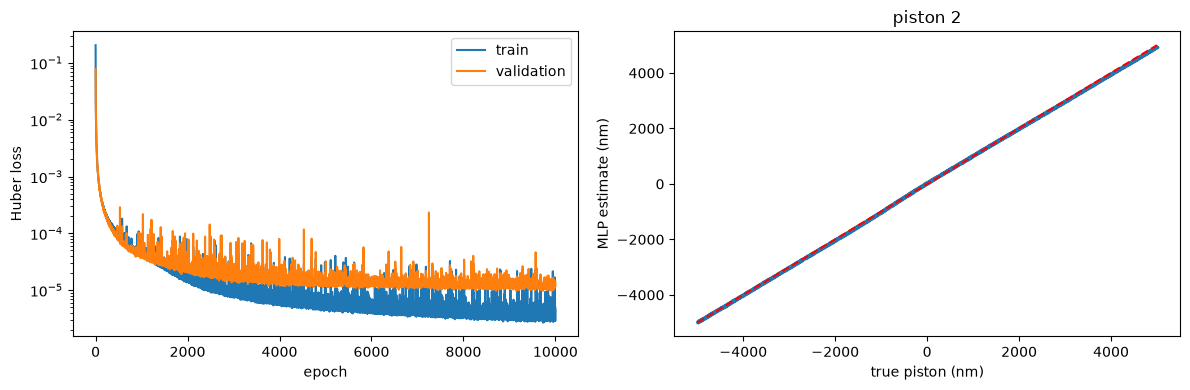

In [3]:
LAYERS = [Xtr.shape[1], 256, 256, 256, 256, M_MODES]
EPOCHS, LR = 10000, 3e-4        # ~5 min on a GPU; the validation loss flattens after ~7000 epochs
MLP_FILE = f"{DATA}/cache_spectral/mlp-{'x'.join(map(str, LAYERS))}-e{EPOCHS}-lr{LR:g}.npz"
if os.path.exists(MLP_FILE) and not cache.retrain:
    params, _, extra = ml.load_mlp(MLP_FILE)
    hist = {"train": extra["train"], "val": extra["val"], "best_epoch": int(extra["best_epoch"])}
else:
    params, hist = ml.train_mlp(LAYERS, Xtr, Ytr, Xva, Yva, epochs=EPOCHS, learning_rate=LR)
    os.makedirs(os.path.dirname(MLP_FILE), exist_ok=True)
    ml.save_mlp(MLP_FILE, params, LAYERS, train=hist["train"], val=hist["val"],
                best_epoch=hist["best_epoch"])
print(f"best epoch {hist['best_epoch']}")
record("MLP", np.asarray(ml.mlp_forward(params, Xva)))

C_mlp = ys.inverse(np.asarray(ml.mlp_forward(params, Xva)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["train"], label="train"); ax[0].plot(hist["val"], label="validation")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("Huber loss"); ax[0].legend()
k = 2
ax[1].scatter(C_va[:, k], C_mlp[:, k], s=2, alpha=0.3)
ax[1].plot([-PISTON_SPAN_NM, PISTON_SPAN_NM], [-PISTON_SPAN_NM, PISTON_SPAN_NM], "r--")
ax[1].set_xlabel("true piston (nm)"); ax[1].set_ylabel("MLP estimate (nm)"); ax[1].set_title(f"piston {k}")
plt.tight_layout(); plt.show()

## Baselines: linear reconstructor and k-nearest neighbours

In [4]:
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

record("linear", cache("linear", lambda: Ridge(1.0).fit(Xtr, Ytr)).predict(Xva))
record("kNN", cache("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(Xtr, Ytr)).predict(Xva))

C:\Users\fabio\miniforge3\envs\plrec\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


[cache] loaded linear
linear           mean  2795.8 nm   per mode [2796.8 2804.1 2761.5 2816.6 2800. ]


C:\Users\fabio\miniforge3\envs\plrec\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator KNeighborsRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


[cache] loaded kNN


kNN              mean  1231.0 nm   per mode [1255.7 1213.2 1202.6 1254.9 1228.5]


## Dense degree-2 polynomial ridge on a wavelength subset

Every degree-2 monomial of the core signals at every `WL_STRIDE`-th
wavelength (raw signals, or their per-wavelength Zernike projection with
`REPR = "zern"`), one ridge per piston. The number of terms grows
quadratically with the inputs and the memory linearly with the rows, so the
fit uses a random `DATA_SHARE` of the training and validation rows and
checks the memory needed first.

In [5]:
WL_STRIDE, DEGREE = 4, 2
DATA_SHARE, MEM_BUDGET_GIB = 0.15, 128.0
wl_fit = np.arange(0, n_wl, WL_STRIDE)

# core-signal features at the fitted wavelengths (the zern branch is retired)
to_features = lambda S: S[:, wl_fit].reshape(len(S), -1)
fs = ml.Standardizer(eps=1e-9).fit(to_features(S_tr))
fit_rows = ml.subsample_rows(len(S_tr), DATA_SHARE, seed=0)
val_rows = ml.subsample_rows(len(S_va), DATA_SHARE, seed=1)
F_fit, F_val = fs.transform(to_features(S_tr[fit_rows])), fs.transform(to_features(S_va[val_rows]))

n_terms = ml.n_poly_terms(F_fit.shape[1], DEGREE)
need_gib = (1.5 * len(F_fit) + len(F_val)) * n_terms * 8 / 2**30   # RidgeCV needs ~0.5x Z_fit extra
print(f"{len(wl_fit)} wavelengths x {F_fit.shape[1] // len(wl_fit)} fiber = {F_fit.shape[1]} inputs "
      f"-> {n_terms:,} terms; {len(F_fit)} fit / {len(F_val)} val rows -> ~{need_gib:.1f} GiB")
assert need_gib <= MEM_BUDGET_GIB, "lower DATA_SHARE (linear) or raise WL_STRIDE (quadratic)"

ridge = cache(f"fiber-ridge-d{DEGREE}-w{len(wl_fit)}-n{len(F_fit)}",
              lambda: ml.fit_dense_poly_ridge(F_fit, Ytr[fit_rows], DEGREE, alphas=np.logspace(-2, 6, 17)))
name = f"fiber-ridge-d{DEGREE}"
RESULTS[name] = ml.rmse_nm(ys.inverse(ml.predict_dense_poly_ridge(ridge, F_val)), C_va[val_rows])
print(f"{name:16s} mean {RESULTS[name].mean():7.1f} nm   per mode {np.round(RESULTS[name], 1)}"
      f"   (on {len(val_rows)} validation rows)")

11 wavelengths x 19 fiber = 209 inputs -> 22,154 terms; 6000 fit / 1500 val rows -> ~1.7 GiB


[cache] loaded fiber-ridge-d2-w11-n6000


C:\Users\fabio\miniforge3\envs\plrec\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator PolynomialFeatures from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\fabio\miniforge3\envs\plrec\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\fabio\miniforge3\envs\plrec\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RidgeCV from version 1.9.0 when using version 1

fiber-ridge-d2   mean   969.0 nm   per mode [ 983.3 1060.9  733.5 1021.5 1045.9]   (on 1500 validation rows)


## Comparison

  no skill (mean)   2893.1 nm   per mode [2888.3 2880.8 2891.4 2908.6 2896.3]
  MLP                 10.2 nm   per mode [ 6.5  5.1 25.3  6.8  7.5]
  linear            2795.8 nm   per mode [2796.8 2804.1 2761.5 2816.6 2800. ]
  kNN               1231.0 nm   per mode [1255.7 1213.2 1202.6 1254.9 1228.5]
  fiber-ridge-d2     969.0 nm   per mode [ 983.3 1060.9  733.5 1021.5 1045.9]


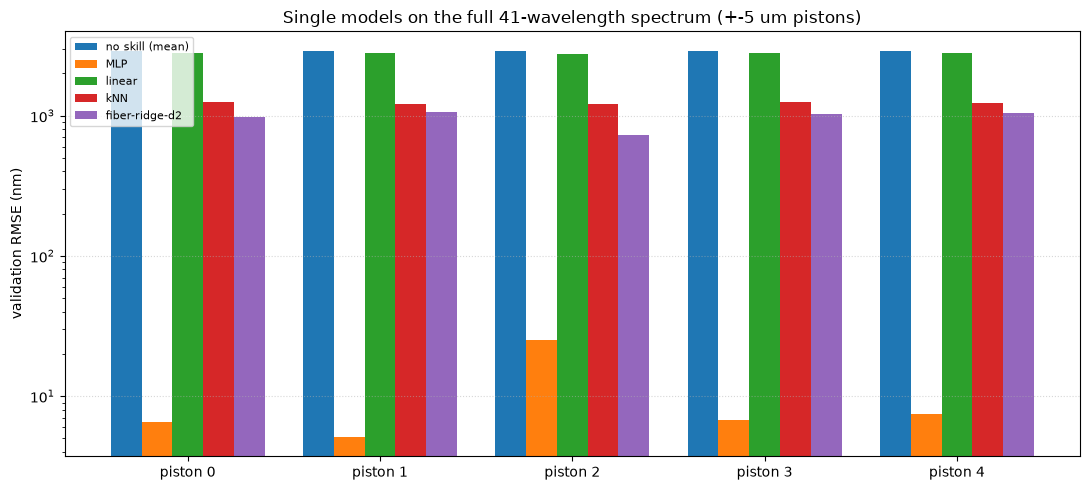

In [6]:
names = list(RESULTS)
for m in names:
    print(f"  {m:16s} {RESULTS[m].mean():7.1f} nm   per mode {np.round(RESULTS[m], 1)}")
x, w = np.arange(M_MODES), 0.8 / len(names)
plt.figure(figsize=(11, 5))
for i, m in enumerate(names):
    plt.bar(x + (i - len(names) / 2 + 0.5) * w, RESULTS[m], w, label=m)
plt.yscale("log"); plt.xticks(x, [f"piston {k}" for k in x]); plt.ylabel("validation RMSE (nm)")
plt.title("Single models on the full 41-wavelength spectrum (+-5 um pistons)")
plt.legend(fontsize=8); plt.grid(True, axis="y", ls=":", alpha=0.5); plt.tight_layout(); plt.show()